**PROYECTO FINAL**
Mariana Giraldo Gil
Valentina Garcia Obando

## 1. Revisión teórica: extracción de características

La extracción de características constituye una etapa fundamental en los sistemas de clasificación de señales electrocardiográficas (ECG), debido a que permite representar las propiedades relevantes de la señal mediante variables que posteriormente pueden utilizarse en modelos de aprendizaje automático. En el artículo *Optimal Multi-Stage Arrhythmia Classification Approach*, Zheng et al. (2020) discuten diferentes estrategias utilizadas para representar la información electrocardiográfica, incluyendo el aprendizaje de características mediante redes neuronales y la extracción tradicional de características morfológicas.

Entre las características morfológicas convencionalmente utilizadas se encuentran las magnitudes de los picos, sus duraciones, las distancias entre ellos y la variabilidad de dichas medidas. Estas características se obtienen a partir de los componentes principales del electrocardiograma, incluyendo la onda P, la onda Q, la onda T y el complejo QRS. Sin embargo, los autores señalan que este tipo de representación puede resultar insuficiente para lograr una clasificación precisa de determinados tipos de arritmias, particularmente aquellas en las que algunas estructuras de la señal presentan deformaciones o desaparecen completamente.

Un ejemplo mencionado en el artículo corresponde a la fibrilación auricular (AFIB) y al flutter auricular (AFL). En estas condiciones, las ondas P pueden ser reemplazadas por múltiples ondas de fibrilación o flutter, las cuales presentan amplitudes inferiores a las de una onda P normal y no mantienen una correspondencia regular con los complejos QRS. Esta alteración dificulta la identificación de las ondas auriculares y limita la utilidad de características que dependen directamente de su detección, medición de amplitud, duración o separación temporal.

Por lo tanto, cuando determinadas formas de onda no se encuentran claramente definidas, la extracción tradicional de características morfológicas puede perder información relevante o producir medidas inconsistentes entre registros. Asimismo, los autores señalan que las características obtenidas mediante transformadas Wavelet o Fourier pueden omitir información del dominio temporal, lo cual constituye otra limitación cuando se pretende caracterizar señales con comportamientos variables y estructuras morfológicas alteradas.

En consecuencia, el artículo destaca la necesidad de utilizar representaciones de la señal que permitan capturar información relevante para la diferenciación de las arritmias, sin depender exclusivamente de la identificación individual de componentes morfológicos que pueden estar deformados o ausentes. Esta consideración resulta especialmente importante en el desarrollo de sistemas automatizados de clasificación electrocardiográfica, debido a que las alteraciones propias de las patologías pueden modificar la estructura convencional de las ondas del ECG.

**Referencia:**

Zheng et al. *Optimal Multi-Stage Arrhythmia Classification Approach*. Scientific Reports, 2020. https://www.nature.com/articles/s41598-020-59821-7

## 2. Filtrado de arritmias para derivación II

In [2]:

# ============================================================
# PROYECTO FINAL - BIOSEÑALES Y SISTEMAS
# PUNTO 2: SELECCIÓN Y EXTRACCIÓN DE LA MUESTRA ECG
# ============================================================

import os
import zipfile
import pandas as pd
from pathlib import PurePosixPath
from collections import defaultdict

# ------------------------------------------------------------
# 1. CONFIGURACIÓN
# ------------------------------------------------------------

RUTA_DIAGNOSTICOS = "Diagnostics.xlsx"
RUTA_ECG = "ECGData.zip"

CARPETA_SALIDA = "ECGData_muestra"
ARCHIVO_TABLA = "Diagnostics_muestra_2000.csv"

EDAD_MINIMA = 18
N_POR_GRUPO = 500
SEMILLA = 42

# ------------------------------------------------------------
# 2. DEFINICIÓN DE LAS CLASES
# ------------------------------------------------------------

GRUPO_RITMO = {
    "SB": "SB",

    "AFIB": "AFIB",
    "AF": "AFIB",

    "SVT": "GSVT",
    "AT": "GSVT",
    "AVNRT": "GSVT",
    "AVRT": "GSVT",
    "SAAWR": "GSVT",

    "SR": "SR",
    "SA": "SR",

    "ST": "ST"
}

# Clases que se utilizarán en el Proyecto 2
ORDEN_GRUPOS = ["SB", "AFIB", "SR", "GSVT"]

# ------------------------------------------------------------
# 3. VERIFICACIÓN DE ARCHIVOS
# ------------------------------------------------------------

print("=" * 65)
print("VERIFICACIÓN DE ARCHIVOS")
print("=" * 65)

if not os.path.exists(RUTA_DIAGNOSTICOS):
    raise FileNotFoundError(
        f"No se encontró {RUTA_DIAGNOSTICOS}"
    )

if not os.path.exists(RUTA_ECG):
    raise FileNotFoundError(
        f"No se encontró {RUTA_ECG}"
    )

print("Diagnostics.xlsx encontrado")
print("ECGData.zip encontrado")

print(
    "Tamaño del archivo original:",
    round(os.path.getsize(RUTA_ECG) / (1024**2), 2),
    "MB"
)

# ------------------------------------------------------------
# 4. CARGAR INFORMACIÓN CLÍNICA
# ------------------------------------------------------------

diag = pd.read_excel(RUTA_DIAGNOSTICOS)

print("\nDimensiones originales:", diag.shape)

print("\nColumnas disponibles:")
print(diag.columns.tolist())

# Normalizar nombres de registros
diag["FileName"] = (
    diag["FileName"]
    .astype(str)
    .str.strip()
)

# Convertir edad a formato numérico
diag["PatientAge"] = pd.to_numeric(
    diag["PatientAge"],
    errors="coerce"
)

# Asignar grupo a cada registro
diag["Grupo"] = diag["Rhythm"].map(GRUPO_RITMO)

# Verificar ritmos sin clasificación
sin_grupo = diag.loc[
    diag["Grupo"].isna(),
    "Rhythm"
].unique()

if len(sin_grupo) > 0:
    raise ValueError(
        f"Hay ritmos sin clasificación: {sin_grupo}"
    )

# ------------------------------------------------------------
# 5. FILTRAR PACIENTES ADULTOS
# ------------------------------------------------------------

diag_adultos = diag[
    diag["PatientAge"] >= EDAD_MINIMA
].copy()

print("\nRegistros de pacientes adultos:")
print(len(diag_adultos))

# ------------------------------------------------------------
# 6. SELECCIONAR LAS CUATRO CLASES
# ------------------------------------------------------------

diag_adultos = diag_adultos[
    diag_adultos["Grupo"].isin(ORDEN_GRUPOS)
].copy()

print("\nDistribución de las cuatro clases:")
print(
    diag_adultos["Grupo"]
    .value_counts()
    .reindex(ORDEN_GRUPOS, fill_value=0)
)

# ------------------------------------------------------------
# 7. VERIFICAR DISPONIBILIDAD DE REGISTROS
# ------------------------------------------------------------

disponibilidad = (
    diag_adultos["Grupo"]
    .value_counts()
    .reindex(ORDEN_GRUPOS, fill_value=0)
)

insuficientes = disponibilidad[
    disponibilidad < N_POR_GRUPO
]

if len(insuficientes) > 0:
    raise ValueError(
        "No hay suficientes registros para seleccionar "
        f"{N_POR_GRUPO} por grupo:\n{insuficientes}"
    )

# ------------------------------------------------------------
# 8. SELECCIÓN ALEATORIA ESTRATIFICADA
# ------------------------------------------------------------

muestra = (
    diag_adultos
    .groupby("Grupo", group_keys=False)
    .apply(
        lambda grupo: grupo.sample(
            n=N_POR_GRUPO,
            random_state=SEMILLA
        )
    )
    .reset_index(drop=True)
)

# Organizar las clases
muestra["Grupo"] = pd.Categorical(
    muestra["Grupo"],
    categories=ORDEN_GRUPOS,
    ordered=True
)

muestra = muestra.sort_values(
    ["Grupo", "FileName"]
).reset_index(drop=True)

print("\n" + "=" * 65)
print("MUESTRA SELECCIONADA")
print("=" * 65)

print(
    muestra["Grupo"]
    .value_counts()
    .reindex(ORDEN_GRUPOS)
)

print("\nTotal de registros seleccionados:", len(muestra))

# ------------------------------------------------------------
# 9. INDEXAR LOS ARCHIVOS ECG DEL ZIP ORIGINAL
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("INDEXACIÓN DE LOS ARCHIVOS ECG")
print("=" * 65)

indice_archivos = defaultdict(list)

with zipfile.ZipFile(RUTA_ECG, "r") as zip_original:

    archivos_csv = [
        nombre
        for nombre in zip_original.namelist()
        if nombre.lower().endswith(".csv")
    ]

    print(
        "Total de archivos CSV encontrados:",
        len(archivos_csv)
    )

    for ruta in archivos_csv:

        nombre_base = PurePosixPath(ruta).stem

        indice_archivos[nombre_base].append(ruta)

    # --------------------------------------------------------
    # 10. EXTRAER LOS ECG SELECCIONADOS
    # --------------------------------------------------------

    os.makedirs(CARPETA_SALIDA, exist_ok=True)

    encontrados = 0
    no_encontrados = []
    duplicados_nombre = []

    print("\nExtrayendo señales seleccionadas...")

    for _, registro in muestra.iterrows():

        nombre = str(registro["FileName"]).strip()

        nombre_base = os.path.splitext(nombre)[0]

        coincidencias = indice_archivos.get(
            nombre_base,
            []
        )

        if len(coincidencias) == 0:

            no_encontrados.append(nombre)

            continue

        if len(coincidencias) > 1:

            duplicados_nombre.append(nombre)

            continue

        ruta_original = coincidencias[0]

        contenido = zip_original.read(ruta_original)

        ruta_destino = os.path.join(
            CARPETA_SALIDA,
            nombre_base + ".csv"
        )

        with open(ruta_destino, "wb") as archivo:

            archivo.write(contenido)

        encontrados += 1

# ------------------------------------------------------------
# 11. GUARDAR LA TABLA CLÍNICA
# ------------------------------------------------------------

muestra.to_csv(
    ARCHIVO_TABLA,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 12. INFORME FINAL DE LA SELECCIÓN
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("RESULTADOS DEL PROCESO")
print("=" * 65)

print("Registros seleccionados:", len(muestra))
print("ECG encontrados y extraídos:", encontrados)
print("ECG no encontrados:", len(no_encontrados))
print("Nombres duplicados en el ZIP:", len(duplicados_nombre))

if no_encontrados:

    print("\nRegistros sin archivo correspondiente:")

    print(no_encontrados[:20])

if duplicados_nombre:

    print("\nRegistros con nombres duplicados:")

    print(duplicados_nombre[:20])

print("\nDistribución definitiva:")

resumen = (
    muestra.groupby("Grupo", observed=False)
    .agg(
        Registros=("FileName", "count"),
        Edad_promedio=("PatientAge", "mean"),
        Edad_minima=("PatientAge", "min"),
        Edad_maxima=("PatientAge", "max"),
        Mujeres=("Gender", lambda x: (x == "FEMALE").sum()),
        Hombres=("Gender", lambda x: (x == "MALE").sum())
    )
)

print(resumen.round(2))

print("\nArchivos generados:")

print("Carpeta de ECG:", CARPETA_SALIDA)
print("Tabla clínica:", ARCHIVO_TABLA)

print("\nPROCESO FINALIZADO.")


VERIFICACIÓN DE ARCHIVOS
Diagnostics.xlsx encontrado
ECGData.zip encontrado
Tamaño del archivo original: 719.62 MB

Dimensiones originales: (10646, 16)

Columnas disponibles:
['FileName', 'Rhythm', 'Beat', 'PatientAge', 'Gender', 'VentricularRate', 'AtrialRate', 'QRSDuration', 'QTInterval', 'QTCorrected', 'RAxis', 'TAxis', 'QRSCount', 'QOnset', 'QOffset', 'TOffset']

Registros de pacientes adultos:
10381

Distribución de las cuatro clases:
Grupo
SB      3871
AFIB    2225
SR      2081
GSVT     721
Name: count, dtype: int64

MUESTRA SELECCIONADA
Grupo
SB      500
AFIB    500
SR      500
GSVT    500
Name: count, dtype: int64

Total de registros seleccionados: 2000

INDEXACIÓN DE LOS ARCHIVOS ECG
Total de archivos CSV encontrados: 10646

Extrayendo señales seleccionadas...


C:\Users\giral\AppData\Local\Temp\ipykernel_11004\2984715932.py:169: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(



RESULTADOS DEL PROCESO
Registros seleccionados: 2000
ECG encontrados y extraídos: 2000
ECG no encontrados: 0
Nombres duplicados en el ZIP: 0

Distribución definitiva:
       Registros  Edad_promedio  Edad_minima  Edad_maxima  Mujeres  Hombres
Grupo                                                                      
SB           500          59.43           20           92      186      314
AFIB         500          72.85           26           94      211      289
SR           500          53.31           18           88      295      205
GSVT         500          58.38           20           96      256      244

Archivos generados:
Carpeta de ECG: ECGData_muestra
Tabla clínica: Diagnostics_muestra_2000.csv

PROCESO FINALIZADO.


In [3]:

# ============================================================
# CORRECCIÓN: LIMPIAR Y REEXTRAER LA MUESTRA DEFINITIVA
# ============================================================

import shutil
import os
import zipfile
from pathlib import PurePosixPath
from collections import defaultdict

# ------------------------------------------------------------
# 1. ELIMINAR LA CARPETA DE EXTRACCIÓN ANTERIOR
# ------------------------------------------------------------

if os.path.exists(CARPETA_SALIDA):

    shutil.rmtree(CARPETA_SALIDA)

os.makedirs(CARPETA_SALIDA, exist_ok=True)

print("Carpeta anterior eliminada y carpeta nueva creada.")

# ------------------------------------------------------------
# 2. INDEXAR LOS ARCHIVOS DEL ZIP ORIGINAL
# ------------------------------------------------------------

indice_archivos = defaultdict(list)

with zipfile.ZipFile(RUTA_ECG, "r") as zip_original:

    archivos_csv = [
        nombre
        for nombre in zip_original.namelist()
        if nombre.lower().endswith(".csv")
    ]

    for ruta in archivos_csv:

        nombre_base = PurePosixPath(ruta).stem

        indice_archivos[nombre_base].append(ruta)

    # --------------------------------------------------------
    # 3. EXTRAER ÚNICAMENTE LOS REGISTROS DE LA MUESTRA
    # --------------------------------------------------------

    encontrados = 0
    no_encontrados = []
    duplicados_nombre = []

    for _, registro in muestra.iterrows():

        nombre = str(registro["FileName"]).strip()

        nombre_base = os.path.splitext(nombre)[0]

        coincidencias = indice_archivos.get(
            nombre_base,
            []
        )

        if len(coincidencias) == 0:

            no_encontrados.append(nombre)

            continue

        if len(coincidencias) > 1:

            duplicados_nombre.append(nombre)

            continue

        ruta_original = coincidencias[0]

        contenido = zip_original.read(ruta_original)

        ruta_destino = os.path.join(
            CARPETA_SALIDA,
            nombre_base + ".csv"
        )

        with open(ruta_destino, "wb") as archivo:

            archivo.write(contenido)

        encontrados += 1

# ------------------------------------------------------------
# 4. RESULTADOS
# ------------------------------------------------------------

archivos_ecg = sorted(
    [
        os.path.join(CARPETA_SALIDA, archivo)
        for archivo in os.listdir(CARPETA_SALIDA)
        if archivo.lower().endswith(".csv")
    ]
)

print("=" * 65)
print("REEXTRACCIÓN DEFINITIVA")
print("=" * 65)

print("Registros seleccionados:", len(muestra))
print("ECG extraídos:", encontrados)
print("Archivos presentes en carpeta:", len(archivos_ecg))
print("No encontrados:", len(no_encontrados))
print("Duplicados:", len(duplicados_nombre))

if no_encontrados:

    print("\nRegistros no encontrados:")
    print(no_encontrados[:20])

if duplicados_nombre:

    print("\nRegistros duplicados:")
    print(duplicados_nombre[:20])

if (
    len(muestra) == 2000
    and encontrados == 2000
    and len(archivos_ecg) == 2000
    and len(no_encontrados) == 0
    and len(duplicados_nombre) == 0
):

    print("\nEXTRACCIÓN EXITOSA: 2000 ECG.")

else:

    print("\nEXTRACCIÓN REQUIERE REVISIÓN.")


Carpeta anterior eliminada y carpeta nueva creada.
REEXTRACCIÓN DEFINITIVA
Registros seleccionados: 2000
ECG extraídos: 2000
Archivos presentes en carpeta: 2000
No encontrados: 0
Duplicados: 0

EXTRACCIÓN EXITOSA: 2000 ECG.


In [4]:

# ============================================================
# PUNTO 2 - CARACTERIZACIÓN Y CONTROL DE CALIDAD
# ============================================================

import os
import glob
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. IDENTIFICAR LOS ARCHIVOS ECG
# ------------------------------------------------------------

archivos_ecg = sorted(
    glob.glob(os.path.join(CARPETA_SALIDA, "*.csv"))
)

diagnosticos_muestra = pd.read_csv(ARCHIVO_TABLA)

print("=" * 70)
print("CARACTERIZACIÓN Y CONTROL DE CALIDAD DE LA BASE ECG")
print("=" * 70)

print("Archivos ECG encontrados:", len(archivos_ecg))
print("Registros clínicos:", len(diagnosticos_muestra))

# ------------------------------------------------------------
# 2. PREPARAR LISTAS DE RESULTADOS
# ------------------------------------------------------------

resultados_calidad = []

# ------------------------------------------------------------
# 3. RECORRER TODOS LOS REGISTROS ECG
# ------------------------------------------------------------

for archivo in archivos_ecg:

    nombre = os.path.splitext(
        os.path.basename(archivo)
    )[0]

    try:

        # Leer archivo ECG
        ecg = pd.read_csv(
            archivo,
            header=0
        )

        # Guardar dimensiones originales
        filas = ecg.shape[0]
        columnas = ecg.shape[1]

        # Verificar presencia de derivación II
        tiene_II = "II" in ecg.columns

        if tiene_II:

            # Convertir derivación II a valores numéricos
            senal_II = pd.to_numeric(
                ecg["II"],
                errors="coerce"
            )

            # Número de valores faltantes
            faltantes_II = senal_II.isna().sum()

            # Número de muestras válidas
            muestras_validas = senal_II.notna().sum()

            # Estadísticas básicas de la derivación II
            if muestras_validas > 0:

                amplitud_minima = senal_II.min()
                amplitud_maxima = senal_II.max()
                amplitud_media = senal_II.mean()
                desviacion = senal_II.std()

            else:

                amplitud_minima = np.nan
                amplitud_maxima = np.nan
                amplitud_media = np.nan
                desviacion = np.nan

        else:

            faltantes_II = np.nan
            muestras_validas = 0
            amplitud_minima = np.nan
            amplitud_maxima = np.nan
            amplitud_media = np.nan
            desviacion = np.nan

        # ----------------------------------------------------
        # VERIFICAR ESTRUCTURA COMPLETA
        # ----------------------------------------------------

        estructura_12 = columnas == 12

        # ----------------------------------------------------
        # REGISTRAR RESULTADOS
        # ----------------------------------------------------

        resultados_calidad.append({

            "FileName": nombre,

            "Filas": filas,

            "Columnas": columnas,

            "Tiene_derivacion_II": tiene_II,

            "Muestras_validas_II": muestras_validas,

            "Valores_faltantes_II": faltantes_II,

            "Estructura_12_derivaciones": estructura_12,

            "Amplitud_minima_II": amplitud_minima,

            "Amplitud_maxima_II": amplitud_maxima,

            "Amplitud_media_II": amplitud_media,

            "Desviacion_II": desviacion

        })

    except Exception as error:

        resultados_calidad.append({

            "FileName": nombre,

            "Filas": np.nan,

            "Columnas": np.nan,

            "Tiene_derivacion_II": False,

            "Muestras_validas_II": 0,

            "Valores_faltantes_II": np.nan,

            "Estructura_12_derivaciones": False,

            "Amplitud_minima_II": np.nan,

            "Amplitud_maxima_II": np.nan,

            "Amplitud_media_II": np.nan,

            "Desviacion_II": np.nan

        })

        print(f"Error en {nombre}: {error}")

# ------------------------------------------------------------
# 4. CREAR TABLA DE CONTROL DE CALIDAD
# ------------------------------------------------------------

revision_ecg = pd.DataFrame(
    resultados_calidad
)

print("\n" + "=" * 70)
print("RESULTADOS DEL CONTROL DE CALIDAD")
print("=" * 70)

print("\nNúmero de registros analizados:")
print(len(revision_ecg))

print("\nRegistros que contienen derivación II:")
print(
    revision_ecg["Tiene_derivacion_II"]
    .value_counts()
)

print("\nRegistros con 12 derivaciones:")
print(
    revision_ecg["Estructura_12_derivaciones"]
    .value_counts()
)

print("\nRegistros con valores faltantes en derivación II:")
print(
    (revision_ecg["Valores_faltantes_II"] > 0)
    .sum()
)

print("\nDistribución del número de muestras:")

print(
    revision_ecg["Filas"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# 5. IDENTIFICAR REGISTROS QUE REQUIEREN REVISIÓN
# ------------------------------------------------------------

registros_revision = revision_ecg[
    (
        revision_ecg["Tiene_derivacion_II"] == False
    ) |
    (
        revision_ecg["Valores_faltantes_II"] > 0
    ) |
    (
        revision_ecg["Estructura_12_derivaciones"] == False
    )
]

print("\n" + "=" * 70)
print("REGISTROS QUE REQUIEREN REVISIÓN")
print("=" * 70)

print("Cantidad:", len(registros_revision))

if len(registros_revision) > 0:

    print(registros_revision)

else:

    print("No se identificaron registros con los criterios evaluados.")

# ------------------------------------------------------------
# 6. GUARDAR TABLAS DE CONTROL
# ------------------------------------------------------------

revision_ecg.to_csv(
    "Control_calidad_ECG.csv",
    index=False,
    encoding="utf-8-sig"
)

registros_revision.to_csv(
    "Registros_revision_ECG.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nTablas guardadas:")
print("Control_calidad_ECG.csv")
print("Registros_revision_ECG.csv")


CARACTERIZACIÓN Y CONTROL DE CALIDAD DE LA BASE ECG
Archivos ECG encontrados: 2000
Registros clínicos: 2000

RESULTADOS DEL CONTROL DE CALIDAD

Número de registros analizados:
2000

Registros que contienen derivación II:
Tiene_derivacion_II
True    2000
Name: count, dtype: int64

Registros con 12 derivaciones:
Estructura_12_derivaciones
True    2000
Name: count, dtype: int64

Registros con valores faltantes en derivación II:
0

Distribución del número de muestras:
Filas
5000    2000
Name: count, dtype: int64

REGISTROS QUE REQUIEREN REVISIÓN
Cantidad: 0
No se identificaron registros con los criterios evaluados.

Tablas guardadas:
Control_calidad_ECG.csv
Registros_revision_ECG.csv


In [5]:

# ============================================================
# RESUMEN ESTADÍSTICO DE LA BASE DE DATOS
# ============================================================

print("=" * 70)
print("RESUMEN ESTADÍSTICO DE LA BASE DE DATOS")
print("=" * 70)

# ------------------------------------------------------------
# 1. DISTRIBUCIÓN DE LAS CLASES
# ------------------------------------------------------------

distribucion_clases = (
    diagnosticos_muestra["Grupo"]
    .value_counts()
    .reindex(ORDEN_GRUPOS, fill_value=0)
)

print("\nDistribución de las clases:")

print(distribucion_clases)

# ------------------------------------------------------------
# 2. DISTRIBUCIÓN POR SEXO
# ------------------------------------------------------------

print("\nDistribución por sexo:")

print(
    diagnosticos_muestra["Gender"]
    .value_counts(dropna=False)
)

# ------------------------------------------------------------
# 3. DISTRIBUCIÓN DE EDADES
# ------------------------------------------------------------

print("\nEstadísticas de edad:")

print(
    diagnosticos_muestra["PatientAge"]
    .describe()
)

# ------------------------------------------------------------
# 4. RESUMEN DE LA BASE DE DATOS
# ------------------------------------------------------------

resumen_base = pd.DataFrame({

    "Caracteristica": [

        "Número total de registros",

        "Número de clases",

        "Registros por clase",

        "Edad promedio",

        "Edad mínima",

        "Edad máxima",

        "Número de señales ECG",

        "Derivación utilizada"

    ],

    "Valor": [

        len(diagnosticos_muestra),

        diagnosticos_muestra["Grupo"].nunique(),

        N_POR_GRUPO,

        diagnosticos_muestra["PatientAge"].mean(),

        diagnosticos_muestra["PatientAge"].min(),

        diagnosticos_muestra["PatientAge"].max(),

        len(archivos_ecg),

        "II"

    ]

})

print("\nResumen general:")

print(resumen_base.to_string(index=False))

# ------------------------------------------------------------
# 5. GUARDAR RESUMEN
# ------------------------------------------------------------

resumen_base.to_csv(
    "Resumen_base_datos_Proyecto2.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nResumen guardado:")
print("Resumen_base_datos_Proyecto2.csv")


RESUMEN ESTADÍSTICO DE LA BASE DE DATOS

Distribución de las clases:
Grupo
SB      500
AFIB    500
SR      500
GSVT    500
Name: count, dtype: int64

Distribución por sexo:
Gender
MALE      1052
FEMALE     948
Name: count, dtype: int64

Estadísticas de edad:
count    2000.000000
mean       60.992500
std        16.921868
min        18.000000
25%        50.000000
50%        63.000000
75%        73.000000
max        96.000000
Name: PatientAge, dtype: float64

Resumen general:
           Caracteristica    Valor
Número total de registros     2000
         Número de clases        4
      Registros por clase      500
            Edad promedio  60.9925
              Edad mínima       18
              Edad máxima       96
    Número de señales ECG     2000
     Derivación utilizada       II

Resumen guardado:
Resumen_base_datos_Proyecto2.csv


In [6]:

# ============================================================
# VERIFICACIÓN DE CORRESPONDENCIA ECG Y DIAGNÓSTICOS
# ============================================================

# ------------------------------------------------------------
# 1. NOMBRES DE LOS ECG EXTRAÍDOS
# ------------------------------------------------------------

nombres_ecg = {

    os.path.splitext(
        os.path.basename(archivo)
    )[0]

    for archivo in archivos_ecg

}

# ------------------------------------------------------------
# 2. NOMBRES DE LA TABLA CLÍNICA
# ------------------------------------------------------------

nombres_clinicos = {

    os.path.splitext(
        str(nombre)
    )[0]

    for nombre in diagnosticos_muestra["FileName"]

}

# ------------------------------------------------------------
# 3. COMPARAR
# ------------------------------------------------------------

sin_diagnostico = nombres_ecg - nombres_clinicos

sin_archivo_ecg = nombres_clinicos - nombres_ecg

print("=" * 70)
print("CORRESPONDENCIA ENTRE ECG Y DIAGNÓSTICOS")
print("=" * 70)

print("ECG extraídos:", len(nombres_ecg))

print("Registros clínicos:", len(nombres_clinicos))

print("ECG sin diagnóstico:", len(sin_diagnostico))

print("Diagnósticos sin archivo ECG:", len(sin_archivo_ecg))

if len(sin_diagnostico) == 0 and len(sin_archivo_ecg) == 0:

    print("\nCORRESPONDENCIA EXITOSA.")

else:

    print("\nSE REQUIERE REVISIÓN.")
    
    if sin_diagnostico:

        print("\nECG sin diagnóstico:")

        print(list(sin_diagnostico)[:20])

    if sin_archivo_ecg:

        print("\nDiagnósticos sin ECG:")

        print(list(sin_archivo_ecg)[:20])


CORRESPONDENCIA ENTRE ECG Y DIAGNÓSTICOS
ECG extraídos: 2000
Registros clínicos: 2000
ECG sin diagnóstico: 0
Diagnósticos sin archivo ECG: 0

CORRESPONDENCIA EXITOSA.


### Analisis

Para el desarrollo del proyecto se seleccionó una muestra de 2000 registros electrocardiográficos pertenecientes a la base de datos ECGData. La selección se realizó considerando las arritmias definidas previamente en el Proyecto 1 y restringiendo el análisis a pacientes adultos, con edades iguales o superiores a 18 años. Se conformó una muestra de cuatro categorías de ritmo cardíaco: bradicardia sinusal (SB), fibrilación auricular (AFIB), ritmo sinusal (SR) y taquicardia supraventricular genérica (GSVT), con 500 registros por categoría, garantizando una distribución balanceada de las clases.

De acuerdo con los requerimientos del presente proyecto, el análisis de las señales se realizará exclusivamente utilizando la derivación II del electrocardiograma. Por lo tanto, durante la etapa de selección y verificación de los registros se comprobó la disponibilidad de esta derivación en la totalidad de la muestra.

Como parte del control de calidad inicial, se verificó la correspondencia entre los registros electrocardiográficos y la información clínica, la estructura de las señales y la disponibilidad de la derivación de interés. Los resultados obtenidos indicaron la presencia de 2000 archivos ECG y 2000 registros clínicos, con disponibilidad de la derivación II y estructura de 12 derivaciones en los registros analizados. Adicionalmente, no se identificaron valores faltantes en la derivación II.

La caracterización estadística de la muestra permitió identificar una edad promedio de 60,99 ± 16,92 años, con una mediana de 63 años y un rango de edad comprendido entre 18 años y el máximo registrado en la base. Respecto a la distribución por sexo, se identificaron 1052 registros correspondientes a hombres y 948 a mujeres.

La distribución equitativa de las cuatro clases proporciona una estructura balanceada para el desarrollo posterior de los modelos de clasificación. No obstante, esta condición no garantiza por sí sola la ausencia de sesgos asociados a otras variables, por lo que los resultados de clasificación deberán interpretarse considerando las características y limitaciones de la muestra seleccionada.

In [7]:
# ============================================================
# PUNTO 3. FILTRADO DE SEÑALES ECG
# CELDA 1: VERIFICACIÓN DE LA ESTRUCTURA DE LA MUESTRA
# ============================================================

print("COLUMNAS DE LA MUESTRA CLÍNICA:")
print(muestra.columns.tolist())

print("\nPRIMEROS REGISTROS:")
display(muestra.head())

print("\nTIPOS DE DATOS:")
print(muestra.dtypes)

print("\nVARIABLES DISPONIBLES:")
print(muestra.columns.tolist())

print("\nCARPETA DE ECG:")
print(CARPETA_SALIDA)

print("\nARCHIVOS ECG DISPONIBLES:")
print(len(archivos_ecg))

COLUMNAS DE LA MUESTRA CLÍNICA:
['FileName', 'Rhythm', 'Beat', 'PatientAge', 'Gender', 'VentricularRate', 'AtrialRate', 'QRSDuration', 'QTInterval', 'QTCorrected', 'RAxis', 'TAxis', 'QRSCount', 'QOnset', 'QOffset', 'TOffset', 'Grupo']

PRIMEROS REGISTROS:


,FileName,Rhythm,Beat,PatientAge,Gender,VentricularRate,AtrialRate,QRSDuration,QTInterval,QTCorrected,RAxis,TAxis,QRSCount,QOnset,QOffset,TOffset,Grupo
0,MUSE_20180111_160355_88000,SB,ALS TWC,81,FEMALE,50,50,74,496,452,-30,4,9,213,250,461,SB
1,MUSE_20180111_160635_98000,SB,NONE,53,MALE,57,57,88,394,383,29,20,9,217,261,414,SB
2,MUSE_20180111_160647_22000,SB,APB TWC VPB,64,FEMALE,55,55,76,426,407,19,-13,9,223,261,436,SB
3,MUSE_20180111_160729_69000,SB,ALS,70,MALE,59,59,86,448,443,-40,63,10,210,253,434,SB
4,MUSE_20180111_163357_09000,SB,STTU TWC,49,MALE,45,45,116,416,359,67,44,7,209,267,417,SB



TIPOS DE DATOS:
FileName             object
Rhythm               object
Beat                 object
PatientAge            int64
Gender               object
VentricularRate       int64
AtrialRate            int64
QRSDuration           int64
QTInterval            int64
QTCorrected           int64
RAxis                 int64
TAxis                 int64
QRSCount              int64
QOnset                int64
QOffset               int64
TOffset               int64
Grupo              category
dtype: object

VARIABLES DISPONIBLES:
['FileName', 'Rhythm', 'Beat', 'PatientAge', 'Gender', 'VentricularRate', 'AtrialRate', 'QRSDuration', 'QTInterval', 'QTCorrected', 'RAxis', 'TAxis', 'QRSCount', 'QOnset', 'QOffset', 'TOffset', 'Grupo']

CARPETA DE ECG:
ECGData_muestra

ARCHIVOS ECG DISPONIBLES:
2000


In [9]:
# ============================================================
# PUNTO 3. FILTRADO DE SEÑALES ECG
# CELDA 2: SELECCIÓN DE REGISTROS REPRESENTATIVOS
# ============================================================

import pandas as pd

# Grupos que vamos a utilizar para la prueba inicial
grupos_prueba = ["SB", "AFIB", "SR", "GSVT"]

# Selección reproducible de un registro por grupo
registros_prueba = (
    muestra[muestra["Grupo"].isin(grupos_prueba)]
    .groupby("Grupo", observed=True)
    .sample(n=1, random_state=42)
    .sort_values("Grupo")
    .reset_index(drop=True)
)

# Mostrar registros seleccionados
print("REGISTROS SELECCIONADOS PARA VALIDAR EL FILTRADO")
display(registros_prueba[["FileName", "Rhythm", "Grupo"]])

# Verificar cantidad de registros seleccionados
print("\nNúmero de registros seleccionados:", len(registros_prueba))

# Verificar que haya un registro de cada grupo
print("\nDistribución de los registros de prueba:")
print(registros_prueba["Grupo"].value_counts())

REGISTROS SELECCIONADOS PARA VALIDAR EL FILTRADO


,FileName,Rhythm,Grupo
0,MUSE_20180116_130047_54000,SB,SB
1,MUSE_20180116_175418_77000,AFIB,AFIB
2,MUSE_20180209_120620_49000,SR,SR
3,MUSE_20180116_134340_45000,SVT,GSVT



Número de registros seleccionados: 4

Distribución de los registros de prueba:
Grupo
SB      1
AFIB    1
SR      1
GSVT    1
Name: count, dtype: int64


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

plt.rcParams["figure.figsize"] = (14, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

In [12]:
# Rutas de los cuatro registros de prueba
rutas_prueba = [
    os.path.join(CARPETA_SALIDA, nombre + ".csv")
    for nombre in registros_prueba["FileName"]
]

# Leer los archivos
senales_prueba = [pd.read_csv(ruta) for ruta in rutas_prueba]

# Identificar derivación II
candidatos_II = ["II", "ii", "MLII", "MII", "LEAD_II",
                 "Lead II", "ECG_II", "ECG II"]

ecg_original = {}

for i, grupo in enumerate(registros_prueba["Grupo"]):
    df = senales_prueba[i]

    columna_II = next(
        (col for col in candidatos_II if col in df.columns),
        None
    )

    if columna_II is None:
        raise ValueError(f"No se encontró derivación II en {grupo}")

    ecg_original[grupo] = pd.to_numeric(
        df[columna_II], errors="coerce"
    ).to_numpy()

print("Señales preparadas:", list(ecg_original.keys()))

for grupo, señal in ecg_original.items():
    print(f"{grupo}: {len(señal)} muestras")

Señales preparadas: ['SB', 'AFIB', 'SR', 'GSVT']
SB: 5000 muestras
AFIB: 5000 muestras
SR: 5000 muestras
GSVT: 5000 muestras


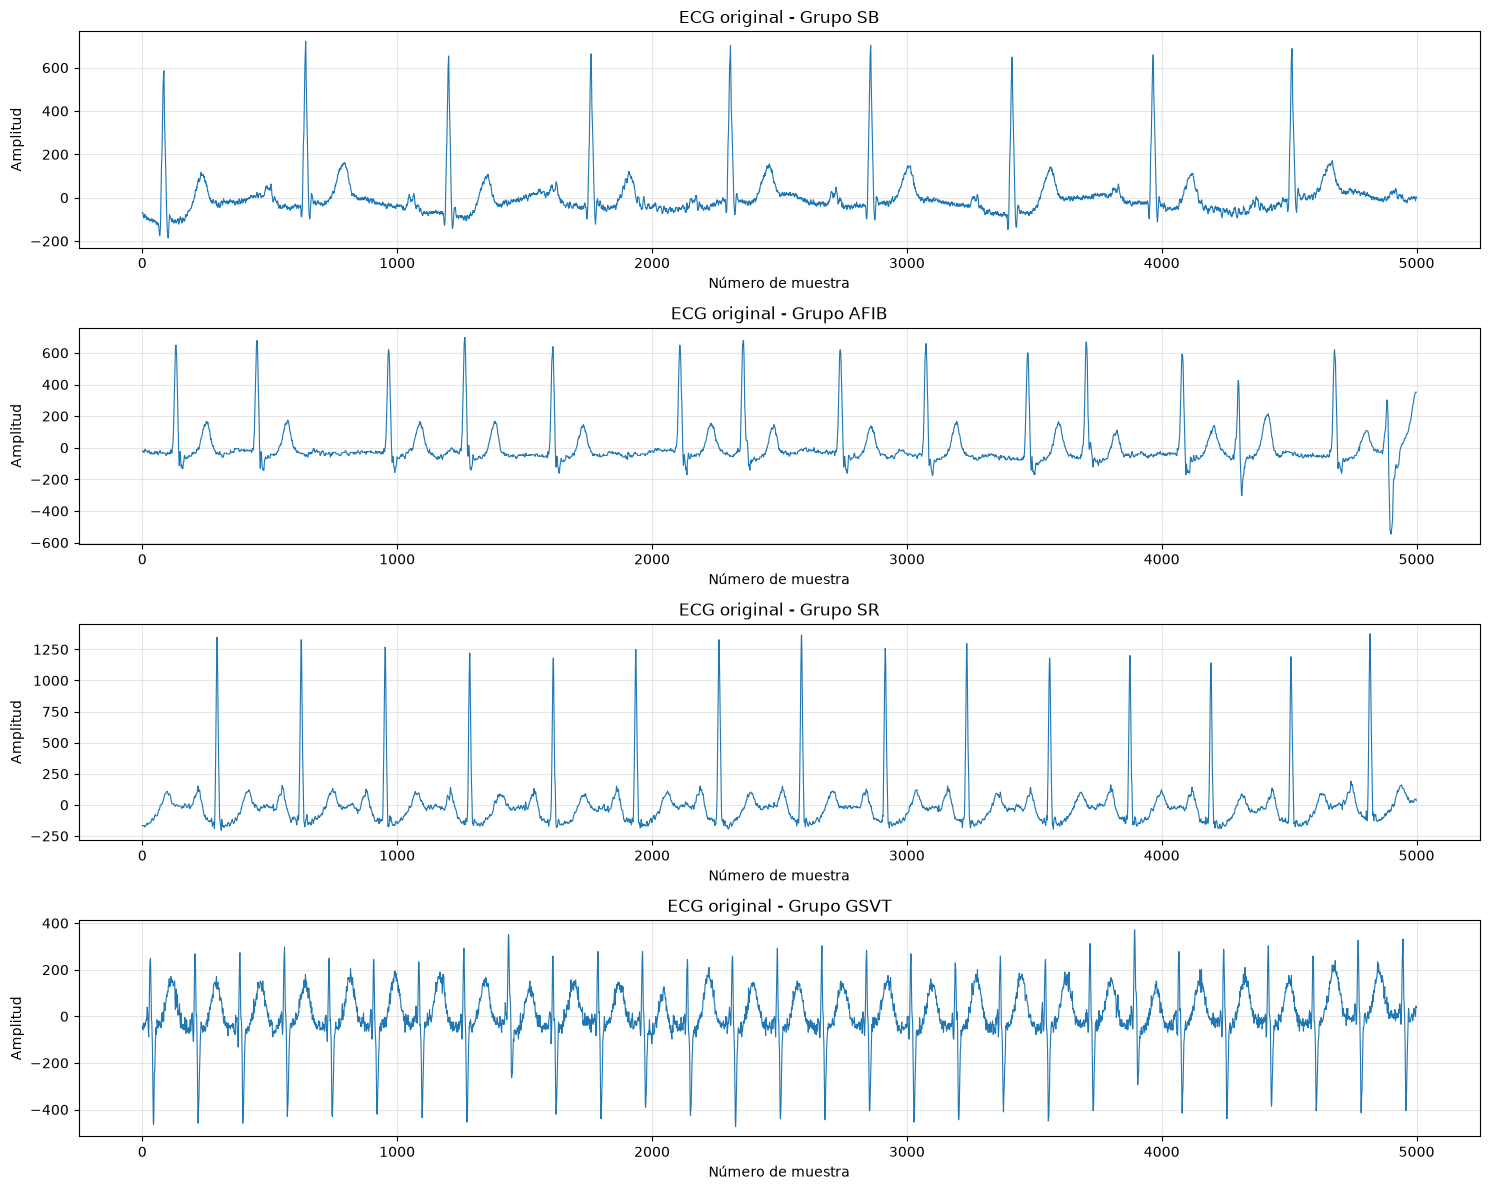

In [13]:
fig, axes = plt.subplots(4, 1, figsize=(15, 12))

for ax, (grupo, señal) in zip(axes, ecg_original.items()):

    ax.plot(señal, linewidth=0.8)
    ax.set_title(f"ECG original - Grupo {grupo}")
    ax.set_xlabel("Número de muestra")
    ax.set_ylabel("Amplitud")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
%pip install statsmodels tqdm

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
    --------------------------------------- 0.3/11.3 MB ? eta -:--:--
   --- ------------------------------------ 1.0/11.3 MB 3.6 MB/s eta 0:00:03
   ------------ --------------------------- 3.4/11.3 MB 6.9 MB/s eta 0:00:02
   ----------------- ---------------------- 5.0/11.3 MB 7.9 MB/s eta 0:00:01
   -------------------------------- ------- 9.2/11.3 MB 10.1 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 10.4 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
# Revisar información disponible de los registros

for i, grupo in enumerate(registros_prueba["Grupo"]):
    print(f"\nGrupo: {grupo}")
    print(f"Archivo: {registros_prueba.iloc[i]['FileName']}")
    print(f"Número de muestras: {len(ecg_original[grupo])}")
    print(f"Columnas disponibles: {senales_prueba[i].columns.tolist()}")


Grupo: SB
Archivo: MUSE_20180116_130047_54000
Número de muestras: 5000
Columnas disponibles: ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

Grupo: AFIB
Archivo: MUSE_20180116_175418_77000
Número de muestras: 5000
Columnas disponibles: ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

Grupo: SR
Archivo: MUSE_20180209_120620_49000
Número de muestras: 5000
Columnas disponibles: ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

Grupo: GSVT
Archivo: MUSE_20180116_134340_45000
Número de muestras: 5000
Columnas disponibles: ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


In [24]:
# ============================================================
# PUNTO 3 - FUNCIONES DE FILTRADO
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import butter, sosfiltfilt
from scipy.ndimage import uniform_filter1d
from statsmodels.nonparametric.smoothers_lowess import lowess
from tqdm.auto import tqdm

# Parámetros provisionales
FS = 500
F_CORTE = 50
ORDEN_BUTTER = 4

FRAC_LOESS = 0.10
RADIO_BUSQUEDA = 10
RADIO_PATCH = 3
H = 1.0


# -------------------------
# 1. Butterworth
# -------------------------
def filtro_butterworth(ecg):

    sos = butter(
        ORDEN_BUTTER,
        F_CORTE,
        btype="lowpass",
        fs=FS,
        output="sos"
    )

    return sosfiltfilt(sos, ecg)


# -------------------------
# 2. LOESS acelerado
# -------------------------
def filtro_loess_rapido(ecg, factor=10):

    n = len(ecg)
    x = np.arange(n)

    indices = np.arange(0, n, factor)
    indices = np.unique(np.append(indices, n - 1))

    baseline_reducida = lowess(
        ecg[indices],
        indices,
        frac=FRAC_LOESS,
        it=1,
        return_sorted=False
    )

    baseline = np.interp(
        x,
        indices,
        baseline_reducida
    )

    return ecg - baseline, baseline


# -------------------------
# 3. NLM vectorizado
# -------------------------
def filtro_nlm_vectorizado(
    ecg,
    radio_busqueda=RADIO_BUSQUEDA,
    radio_patch=RADIO_PATCH,
    h=H
):

    ecg = np.asarray(ecg, dtype=float)
    n = len(ecg)

    d = np.diff(ecg)

    sigma = (
        np.median(np.abs(d - np.median(d)))
        / (0.6745 * np.sqrt(2))
    )

    sigma = max(sigma, 1e-10)
    h_eff = h * sigma

    acumulado = ecg.copy()
    pesos_total = np.ones(n)

    for k in range(1, radio_busqueda + 1):

        for desplazamiento in (k, -k):

            vecino = np.roll(ecg, desplazamiento)

            diferencias = (ecg - vecino)**2

            distancia = uniform_filter1d(
                diferencias,
                size=2*radio_patch + 1,
                mode="reflect"
            )

            pesos = np.exp(
                -distancia / (h_eff**2)
            )

            if desplazamiento > 0:
                pesos[:desplazamiento] = 0
            else:
                pesos[desplazamiento:] = 0

            acumulado += pesos * vecino
            pesos_total += pesos

    return acumulado / pesos_total


# -------------------------
# Pipeline completo
# -------------------------
def pipeline_ecg(ecg):

    ecg_butter = filtro_butterworth(ecg)

    ecg_loess, baseline = filtro_loess_rapido(
        ecg_butter
    )

    ecg_nlm = filtro_nlm_vectorizado(
        ecg_loess
    )

    return {
        "original": ecg,
        "butterworth": ecg_butter,
        "loess": ecg_loess,
        "nlm": ecg_nlm,
        "baseline": baseline
    }

print("Funciones de filtrado cargadas.")

Funciones de filtrado cargadas.


In [25]:
# ============================================================
# PUNTO 3 - FILTRADO DE LOS 2000 REGISTROS
# ============================================================

CARPETA_FILTRADAS = os.path.join(
    os.path.dirname(CARPETA_SALIDA),
    "ECGData_filtrada"
)

os.makedirs(CARPETA_FILTRADAS, exist_ok=True)

# 4 registros de visualización (uno por grupo)
grupos_visualizacion = ["SB", "AFIB", "SR", "GSVT"]

registros_visualizacion = (
    muestra[muestra["Grupo"].isin(grupos_visualizacion)]
    .groupby("Grupo", observed=True)
    .sample(n=1, random_state=42)
    .reset_index(drop=True)
)

nombres_visualizacion = set(
    registros_visualizacion["FileName"]
)

resultados_visualizacion = {}

errores = []
registros_procesados = 0

tiempo_inicio = time.time()

for _, registro in tqdm(
    muestra.iterrows(),
    total=len(muestra),
    desc="Filtrando ECG"
):

    nombre = registro["FileName"]

    ruta = os.path.join(
        CARPETA_SALIDA,
        nombre + ".csv"
    )

    ruta_destino = os.path.join(
        CARPETA_FILTRADAS,
        nombre + ".csv"
    )

    try:

        df = pd.read_csv(ruta)

        ecg = pd.to_numeric(
            df["II"],
            errors="coerce"
        ).to_numpy(dtype=float)

        if not np.isfinite(ecg).all():
            raise ValueError("Valores inválidos en derivación II")

        # Pipeline
        resultado = pipeline_ecg(ecg)

        # Guardar señal filtrada
        df["II_filtrada"] = resultado["nlm"]

        df.to_csv(
            ruta_destino,
            index=False
        )

        registros_procesados += 1

        # Conservar las etapas de 4 señales
        if nombre in nombres_visualizacion:

            resultado["grupo"] = registro["Grupo"]

            resultados_visualizacion[nombre] = resultado

    except Exception as e:

        errores.append({
            "FileName": nombre,
            "Error": str(e)
        })


tiempo_total = time.time() - tiempo_inicio

print("\n" + "="*50)
print("PROCESAMIENTO FINALIZADO")
print("="*50)

print("Registros procesados:", registros_procesados)
print("Registros con errores:", len(errores))
print(f"Tiempo total: {tiempo_total/60:.2f} minutos")
print("Carpeta de salida:", CARPETA_FILTRADAS)

if errores:
    display(pd.DataFrame(errores))

Filtrando ECG: 100%|██████████| 2000/2000 [03:15<00:00, 10.21it/s]


PROCESAMIENTO FINALIZADO
Registros procesados: 2000
Registros con errores: 0
Tiempo total: 3.26 minutos
Carpeta de salida: ECGData_filtrada


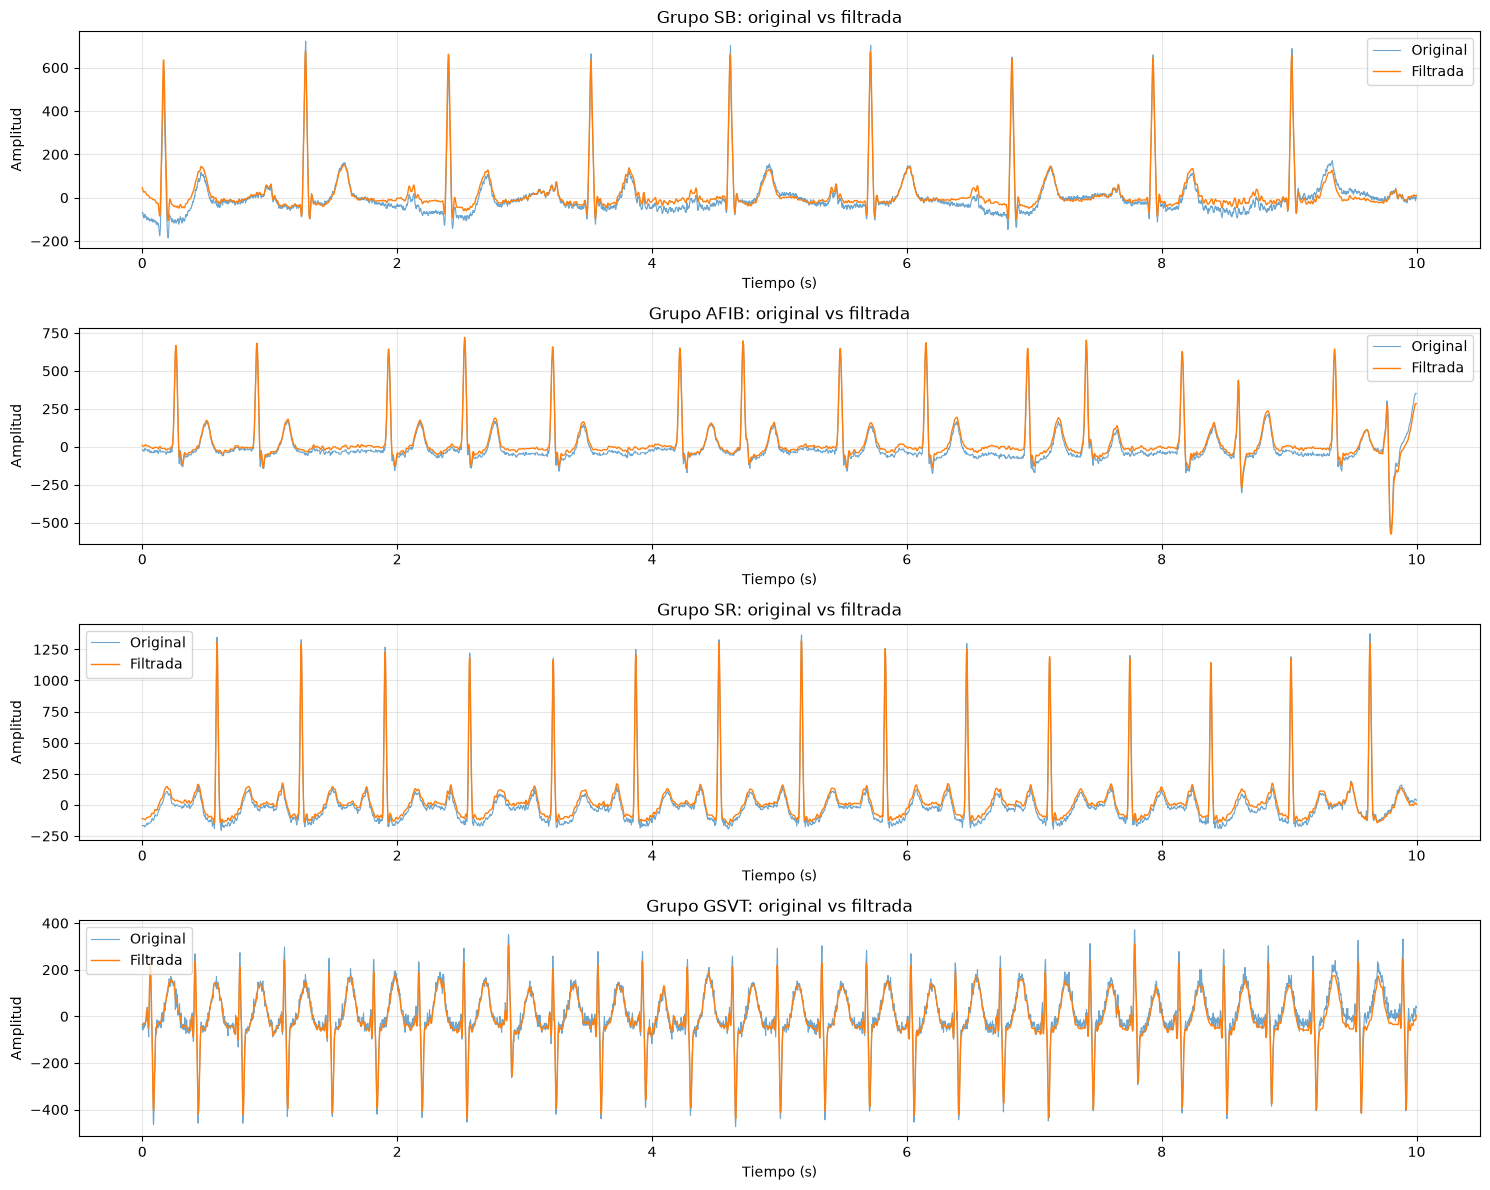

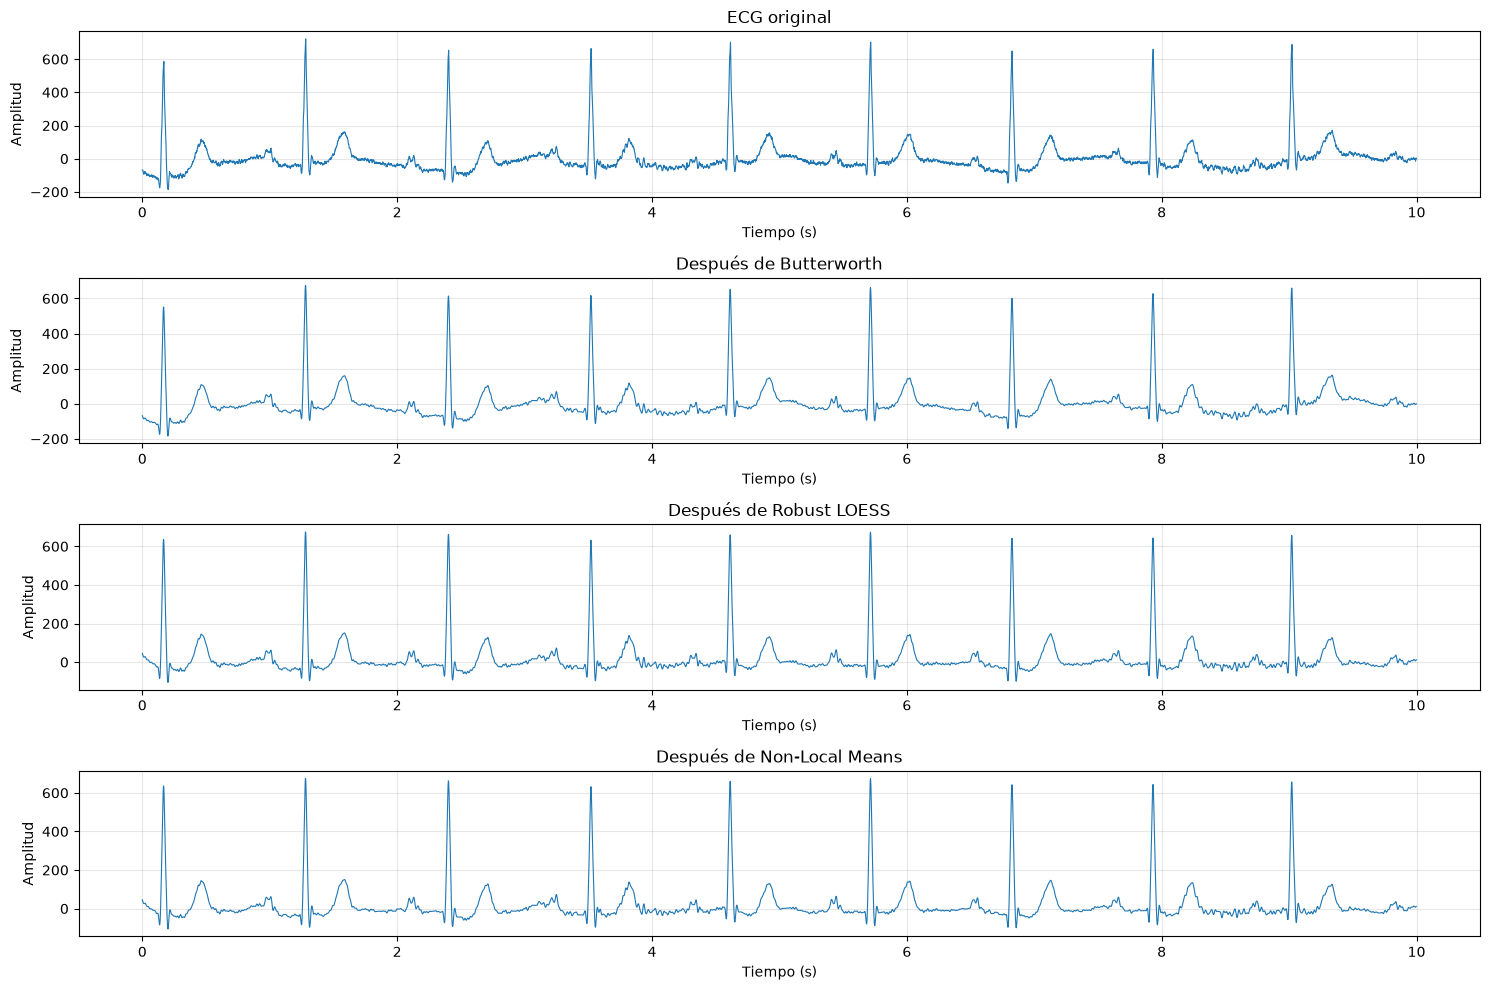

In [26]:
# ============================================================
# PUNTO 3 - VISUALIZACIÓN Y COMPARACIÓN
# ============================================================

# ------------------------------------------------------------
# 1. Original vs filtrada para los 4 grupos
# ------------------------------------------------------------

fig, axes = plt.subplots(
    4, 1,
    figsize=(15, 12)
)

for ax, registro in zip(
    axes,
    registros_visualizacion.itertuples()
):

    nombre = registro.FileName
    grupo = registro.Grupo

    datos = resultados_visualizacion[nombre]

    tiempo = np.arange(
        len(datos["original"])
    ) / FS

    ax.plot(
        tiempo,
        datos["original"],
        label="Original",
        alpha=0.65,
        linewidth=0.8
    )

    ax.plot(
        tiempo,
        datos["nlm"],
        label="Filtrada",
        linewidth=1
    )

    ax.set_title(
        f"Grupo {grupo}: original vs filtrada"
    )

    ax.set_xlabel("Tiempo (s)")
    ax.set_ylabel("Amplitud")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Visualización de las etapas de filtrado
# ------------------------------------------------------------

nombre_ejemplo = registros_visualizacion.iloc[0]["FileName"]

datos = resultados_visualizacion[nombre_ejemplo]

tiempo = np.arange(
    len(datos["original"])
) / FS

fig, axes = plt.subplots(
    4, 1,
    figsize=(15, 10)
)

etapas = [
    ("original", "ECG original"),
    ("butterworth", "Después de Butterworth"),
    ("loess", "Después de Robust LOESS"),
    ("nlm", "Después de Non-Local Means")
]

for ax, (clave, titulo) in zip(
    axes,
    etapas
):

    ax.plot(
        tiempo,
        datos[clave],
        linewidth=0.8
    )

    ax.set_title(titulo)
    ax.set_xlabel("Tiempo (s)")
    ax.set_ylabel("Amplitud")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()